# Standard A shock with a grid-solved time-to-build

An alternative solve of the model in `semi_endo_A.ipynb` under a **standard productivity
shock**: a uniform multiplicative decline in `A` that firms cannot dodge. Calibration
(`c`, `N`, `tau`) and the staggering structure are kept identical to the original, so the
paths here are directly comparable.

Two things are done differently:

1. **The optimal lag is solved on a grid**, by maximizing `(βc)^t (t + N_i)` over all
   integer `t`, rather than by rounding the continuous optimum to `floor`/`ceil`. The two
   agree exactly here (asserted below), which is worth pinning down before any shock is
   layered on.
2. **The shock size is a parameter**, not a literal buried inside the matrix generator, so
   the response can be swept over shock magnitudes.

The main substantive result is the neutrality check in the next section: a uniform
multiplicative `A` shock leaves every firm's optimal lag unchanged, so the endogenous and
exogenous time-to-build solutions coincide and there is only **one** path to plot. Shocks
that do move the lag — to the interest rate, or to `N` — are left for separate notebooks.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## Parameters

In [2]:
sigma = 5
gamma = 1
eta   = 2
power = (1 + eta) / (-gamma - eta)

beta  = 1 / (1.0 + 0.01)
beta1 = 1 / (1.0 + 0.01 * np.exp(30 / (36.5 * 0.9)))
W = 1

SHOCK       = 0.97                # baseline: 3% productivity decline
SHOCK_SIZES = [0.99, 0.97, 0.95]  # 1%, 3%, 5%

## Calibration

Unchanged from `semi_endo_A.ipynb`: choose `c` so the mean gap between the time-to-produce
implied by `beta` and by `beta1` is one period.

In [3]:
data     = pd.read_csv('APP_data_usa_goods.csv', index_col=0)
data_tau = data['invtCogsRatio'] * 36.5 / (30 * 0.1)

c_grid   = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(len(c_grid))

for i, c_try in enumerate(c_grid[1:], start=1):     # skip c=0 (log divergence)
    N_try = -(data_tau) - 1 / np.log(beta * c_try)
    t1 = np.clip(-1 / np.log(beta  * c_try) - N_try, 0, None)
    t2 = np.clip(-1 / np.log(beta1 * c_try) - N_try, 0, None)
    tau_diff[i] = np.mean(np.abs(t1 - t2))

c = np.min(c_grid[np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1))])
print(f'calibrated c = {c:.6f}')

calibrated c = 0.901802


In [4]:
N = np.asarray(-data_tau - 1 / np.log(beta * c))

# floor/ceil rounding, exactly as in semi_endo_A.ipynb
tau = np.clip(-1 / np.log(beta * c) - N, 0, None)
tau_floor, tau_ceil = np.floor(tau), np.ceil(tau)
tprod_ceil  = (beta * c) ** tau_ceil  * (tau_ceil  + N)
tprod_floor = (beta * c) ** tau_floor * (tau_floor + N)
tau = np.where(tprod_ceil > tprod_floor, tau_ceil,
      np.where(tprod_ceil < tprod_floor, tau_floor, tau))
tau = np.clip(tau, 0, None).astype(int)

# same reversal the original applies before building the matrix
tau_v   = tau[::-1].copy()
N_v     = N[::-1].copy()
n_firms = len(tau_v)

print(f'{n_firms} firms, tau in [{tau_v.min()}, {tau_v.max()}]')

269 firms, tau in [0, 13]


## Grid solve for the optimal lag

`V[i, t]` is firm `i`'s productivity from choosing lag `t`. The grid argmax must reproduce
the floor/ceil rounding, otherwise the two notebooks would differ before any shock is applied.

In [5]:
T_GRID = np.arange(0, 60)

def tprod(t, N_x):
    '''Productivity from choosing production lag t.'''
    return (beta * c) ** t * (t + N_x)

V = tprod(T_GRID[None, :], N_v[:, None])

assert np.array_equal(T_GRID[V.argmax(axis=1)], tau_v), \
    'grid argmax disagrees with the floor/ceil rounding'
print('grid argmax reproduces the floor/ceil tau for all firms')

grid argmax reproduces the floor/ceil tau for all firms


## Neutrality of a standard A shock

The optimal lag solves

$$\tau_i^{*} \;=\; \arg\max_t \; A\,(\beta c)^{t}\,(t + N_i)
\qquad\Longrightarrow\qquad
\tau_i^{*} \;=\; -\frac{1}{\log(\beta c)} - N_i$$

`A` scales the objective but does not appear in the argmax, so a uniform multiplicative
productivity shock cannot move any firm's lag — at any magnitude. Endogenous and exogenous
time-to-build therefore give the **same** path here, and `delta`-style splits between firms
that can and cannot re-time have nothing to bite on.

In [6]:
print(f'{"A shock":>9} {"firms re-timing":>17}')
for s in [1.0, 0.99, 0.97, 0.95, 0.50]:
    tau_s = T_GRID[(s * V).argmax(axis=1)]
    print(f'{s:>9.2f} {int((tau_s != tau_v).sum()):>13d}/{n_firms}')

  A shock   firms re-timing
     1.00             0/269
     0.99             0/269
     0.97             0/269
     0.95             0/269
     0.50             0/269


## Staggering structure

Same placement as `generate_pattern_array_with_extra_rows`, but returning a boolean mask of
which (period, firm) cells are shocked, with the shock value supplied separately. The
assertion confirms it rebuilds the original matrix exactly.

In [7]:
def shock_mask(t):
    '''Boolean (period x firm) mask of shocked cells.

    Identical placement to generate_pattern_array_with_extra_rows in semi_endo_A.ipynb;
    only the payload differs (mask instead of a hardcoded shock value).
    '''
    t = np.asarray(t)
    n = len(t) + int(t.min())
    m = int(t.max()) + int(t.min())
    missing_count = len(set(range(int(t.max()) + 1)) - set(t))

    M = np.zeros((m + 2, n + missing_count), dtype=bool)
    count = 0
    for i in range(1, m + 2):
        k = int((t == i - 1).sum())
        for j in range(k):
            M[i, n - i - j - count] = True
        if k > 1:
            count += k - 1

    M = np.vstack([M, np.zeros(n + missing_count, dtype=bool)])
    return M[:, 0:n - int(t.min())]


def generate_pattern_array_with_extra_rows(tau, shock=SHOCK):
    '''Original generator, with the shock literal promoted to an argument.'''
    return np.where(shock_mask(tau), shock, 1.0)


M = shock_mask(tau_v)
print(f'mask {M.shape}: {M.sum()} shocked cells over {M.shape[0]} periods')

mask (16, 269): 268 shocked cells over 16 periods


## Solving the response

In [8]:
tprod_v = tprod(tau_v, N_v)


def solve(shock):
    '''Consumption and inflation paths under a uniform A shock of the given size.'''
    A  = generate_pattern_array_with_extra_rows(tau_v, shock)
    P0 = (np.sum(1 / (A * tprod_v) ** (1 - sigma), axis=1)) ** (1 / (1 - sigma))
    C  = P0 ** power / P0[0] ** power - 1

    C_pad = np.zeros(len(C) + 1)
    C_pad[1:] = C
    pi = -(C_pad[1:] - C_pad[:-1])
    return C, pi


C, pi = solve(SHOCK)
print(f'{100*(1-SHOCK):.0f}% shock: consumption trough {C.min():.5f}, inflation peak {pi.max():.5f}')

3% shock: consumption trough -0.01307, inflation peak 0.00674


In [9]:
# must match the exogenous branch of semi_endo_A.ipynb exactly
A_orig  = np.where(shock_mask(tau_v), 0.97, 1.0)
P0_orig = (np.sum(1 / (A_orig * tprod_v) ** (1 - sigma), axis=1)) ** (1 / (1 - sigma))
C_orig  = P0_orig ** power / P0_orig[0] ** power - 1

assert np.allclose(solve(0.97)[0], C_orig)
print(f'matches semi_endo_A.ipynb exogenous path (max abs diff '
      f'{np.abs(solve(0.97)[0] - C_orig).max():.2e})')

matches semi_endo_A.ipynb exogenous path (max abs diff 0.00e+00)


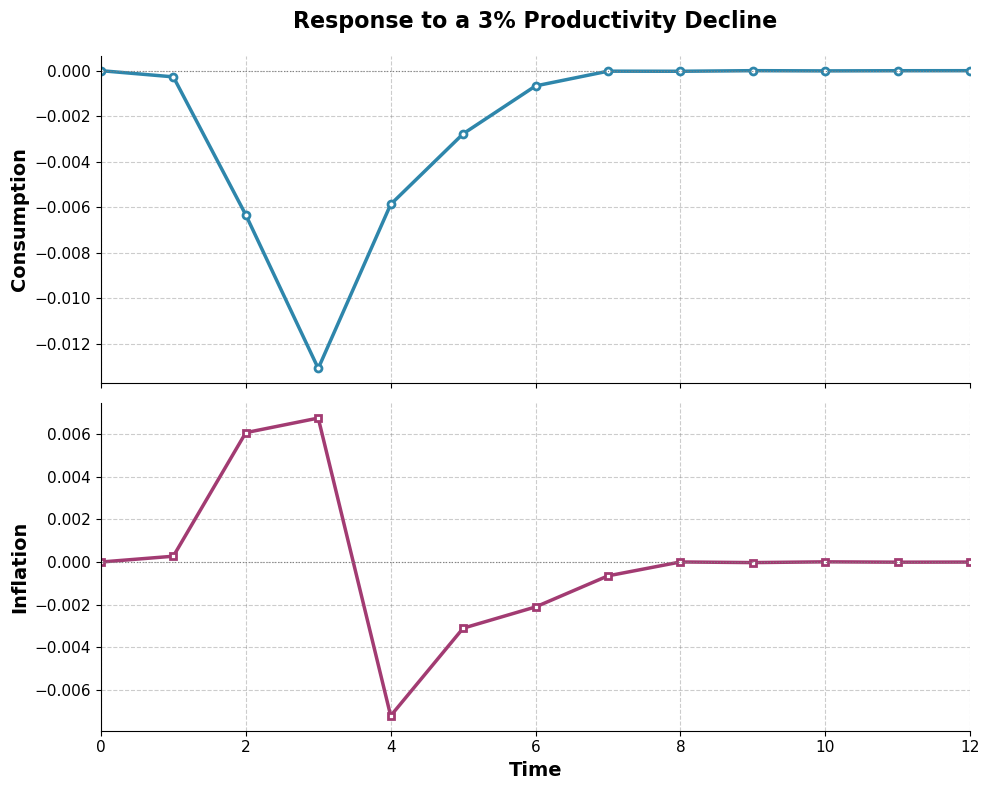

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(C, lw=2.5, marker='o', markersize=5, color='#2E86AB',
         markerfacecolor='white', markeredgewidth=2)
ax2.plot(pi, lw=2.5, marker='s', markersize=5, color='#A23B72',
         markerfacecolor='white', markeredgewidth=2)

ax1.set_title(f'Response to a {100*(1-SHOCK):.0f}% Productivity Decline',
              fontsize=16, weight='bold', pad=20)
ax1.set_ylabel('Consumption', fontsize=14, weight='bold')
ax2.set_ylabel('Inflation', fontsize=14, weight='bold')
ax2.set_xlabel('Time', fontsize=14, weight='bold')

for ax in (ax1, ax2):
    ax.set_xlim(0, 12)
    ax.grid(True, linestyle='--', alpha=0.4, color='gray')
    ax.tick_params(axis='both', which='major', labelsize=11)
    ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../semi_endo_A_standard.png', dpi=150)
plt.show()

## Shock size

The lag distribution is fixed, so the shock size is the only comparative static left in
this experiment.

  shock    C trough     pi peak
     1%    -0.00443     0.00227
     3%    -0.01307     0.00674
     5%    -0.02141     0.01111


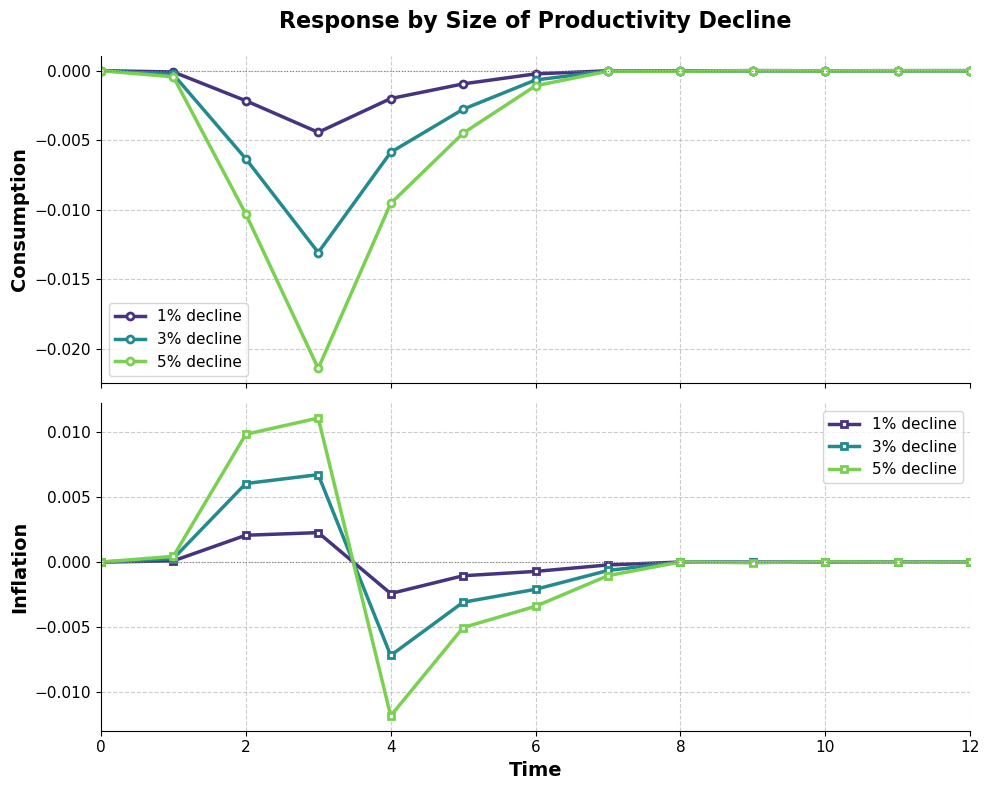

In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
colors = plt.cm.viridis(np.linspace(0.15, 0.8, len(SHOCK_SIZES)))

print(f'{"shock":>7} {"C trough":>11} {"pi peak":>11}')
for s, col in zip(SHOCK_SIZES, colors):
    C_s, pi_s = solve(s)
    lab = f'{100*(1-s):.0f}% decline'
    ax1.plot(C_s,  lw=2.5, marker='o', markersize=5, color=col,
             markerfacecolor='white', markeredgewidth=2, label=lab)
    ax2.plot(pi_s, lw=2.5, marker='s', markersize=5, color=col,
             markerfacecolor='white', markeredgewidth=2, label=lab)
    print(f'{100*(1-s):>6.0f}% {C_s.min():>11.5f} {pi_s.max():>11.5f}')

ax1.set_title('Response by Size of Productivity Decline', fontsize=16, weight='bold', pad=20)
ax1.set_ylabel('Consumption', fontsize=14, weight='bold')
ax2.set_ylabel('Inflation', fontsize=14, weight='bold')
ax2.set_xlabel('Time', fontsize=14, weight='bold')

for ax in (ax1, ax2):
    ax.set_xlim(0, 12)
    ax.grid(True, linestyle='--', alpha=0.4, color='gray')
    ax.tick_params(axis='both', which='major', labelsize=11)
    ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
    ax.legend(fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../semi_endo_A_standard_sizes.png', dpi=150)
plt.show()

## Summary

- Solving the lag on an integer grid reproduces the floor/ceil rounding exactly, so the
  two solution methods agree before any shock.
- A standard multiplicative `A` shock is **neutral for the lag choice** at every magnitude,
  because `A` scales the firm's objective without entering its argmax. Endogenous and
  exogenous time-to-build coincide, and this notebook's path reproduces the exogenous
  branch of `semi_endo_A.ipynb`.
- With the lag distribution pinned down, the size of the decline is the only margin left,
  and consumption and inflation scale close to proportionally in it.

**Next.** Shocks that do move `τ* = -1/log(βc) - N` are the ones where endogenous
time-to-build, and a frozen-firm split, actually change the answer:

- an **interest rate** shock moves `-1/log(βc)` for every firm (r: 1% → 2% shortens the
  target lag by about 0.7 periods and moves ~188 of 269 firms);
- a shock to **N** moves `τ*` one-for-one in the opposite direction.

*Caveat inherited from the original construction:* the staggering places 268 shocked cells
for 269 firms, so one firm is never hit, and 3 of the 268 land on a firm whose `tau` does
not match the period. Preserved here for comparability rather than corrected.